# Group 3 | Seasonal Climatology

**Predicting Drought Before the Rains Fail**

District-level severe meteorological drought, Tanzania (1981–2025).

## 3. Historical drought reconstruction

**Objective.** Locate drought occurrences, quantify their frequency and magnitude, and reconstruct consecutive drought episodes from 1981 to 2025.

Classification uses the supplied rainfall-based SPI-3 index:

- Moderate drought: $-1.5 < \mathrm{SPI3} \leq -1.0$
- Severe drought: $-2.0 < \mathrm{SPI3} \leq -1.5$
- Extreme drought: $\mathrm{SPI3}\leq-2.0$

For baseline evaluation, the severe-event indicator includes both severe and extreme months: $\mathrm{SPI3}\leq-1.5$.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
OUT = ROOT / "outputs"
for name in ["figures", "maps", "metrics", "predictions", "tables"]:
    (OUT / name).mkdir(parents=True, exist_ok=True)

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from group3_climatology.data import load_data
from group3_climatology.historical import classify, historical_tables, drought_episodes, northern_case_study
from group3_climatology.plots import plot_annual, plot_districts, plot_monthly, plot_episode_duration, plot_geographic
from group3_climatology.config import INPUT, GEOGRAPHY

data = load_data(INPUT)
classified = classify(data)
tables = historical_tables(data)
severe_episodes = drought_episodes(data, threshold=-1.5)
all_drought_episodes = drought_episodes(data, threshold=-1.0)
print("Valid SPI-3 observations:", classified.spi3_gamma_ref1981_2010.notna().sum())
print("Severe district-months:", int(classified.is_severe.sum()))
print("Severe episodes:", len(severe_episodes))
print("Longest severe episode (months):", severe_episodes.duration_months.max())

Valid SPI-3 observations: 80700
Severe district-months: 4364
Severe episodes: 2859
Longest severe episode (months): 7


### Where did drought occur most often?

Frequency is computed as severe district-months divided by valid district-months. The result is a meteorological-drought frequency, not a measure of people affected.

,district_id,region,district,valid_spi_months,severe_months,drought_months,extreme_months,lowest_spi3,average_rainfall_mm,severe_frequency
89,1606,Kigoma,Kakonko,538,46.0,88.0,14.0,-3.181148,96.254818,0.085502
97,1805,Kagera,Ngara,538,44.0,81.0,14.0,-3.098309,90.357697,0.081784
103,1904,Mwanza,Kwimba,538,44.0,84.0,15.0,-3.144335,81.631318,0.081784
131,2502,Geita,Nyang'hwale,538,43.0,78.0,12.0,-3.278508,90.479019,0.079926
134,2505,Geita,Chato,538,43.0,81.0,18.0,-2.713516,94.113686,0.079926
96,1804,Kagera,Biharamulo,538,43.0,77.0,23.0,-2.650962,97.120334,0.079926
108,2002,Mara,Serengeti,538,43.0,76.0,18.0,-3.273697,84.433560,0.079926
86,1603,Kigoma,Kigoma,538,43.0,95.0,13.0,-2.737734,114.591813,0.079926
101,1902,Mwanza,Magu,538,41.0,76.0,14.0,-2.660268,97.930134,0.076208
105,1906,Mwanza,Ilemela,538,41.0,82.0,16.0,-2.837977,98.193753,0.076208


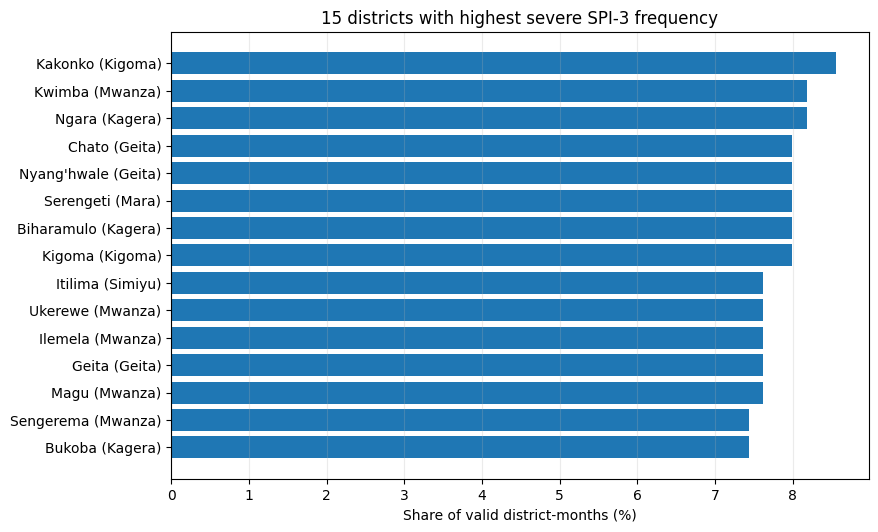

In [2]:
display(tables["district"].sort_values("severe_frequency", ascending=False).head(12))
fig = plot_districts(tables["district"], OUT / "figures" / "highest_frequency_districts.png")
plt.show(); plt.close(fig)

### When did severe drought occur?

Annual proportions identify widespread SPI-3 conditions. Individual monthly counts capture their timing within an annual period.

,year,severe_months,valid_spi_months,extreme_months,severe_frequency
22,2003,291.0,1800,145.0,0.161667
19,2000,258.0,1800,100.0,0.143333
12,1993,230.0,1800,98.0,0.127778
24,2005,225.0,1800,74.0,0.125
36,2017,215.0,1800,81.0,0.119444
18,1999,208.0,1800,67.0,0.115556
25,2006,197.0,1800,110.0,0.109444
16,1997,184.0,1800,87.0,0.102222
3,1984,164.0,1800,58.0,0.091111
34,2015,151.0,1800,70.0,0.083889


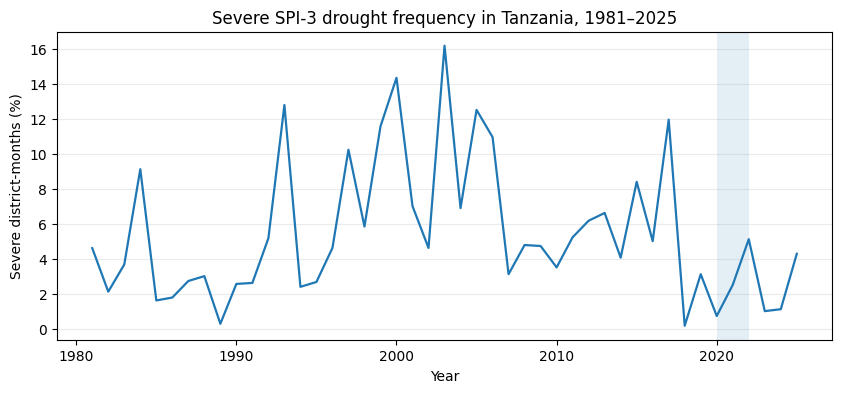

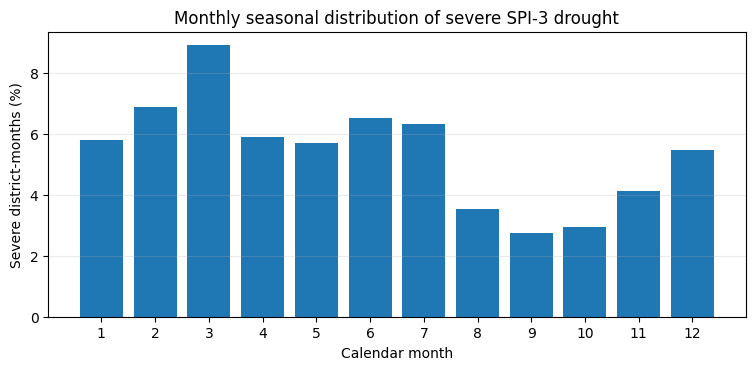

In [3]:
display(tables["annual"].nlargest(10, "severe_frequency"))
fig=plot_annual(tables["annual"], OUT / "figures" / "annual_severe_frequency.png")
plt.show(); plt.close(fig)
fig=plot_monthly(tables["calendar_month"], OUT / "figures" / "calendar_month_frequency.png")
plt.show(); plt.close(fig)

### Duration and severity

An episode is a maximal consecutive sequence of months at or below the chosen SPI-3 threshold within the same district. Missing SPI-3 or a month above the threshold ends an episode.

,district,region,start_month,end_month,duration_months,lowest_spi3
118,Nyamagana,Mwanza,1984-01-01,1984-07-01,7,-2.388088
1680,Tarime,Mara,2005-08-01,2006-02-01,7,-2.277428
117,Ukerewe,Mwanza,1984-01-01,1984-06-01,6,-2.414914
121,Misungwi,Mwanza,1984-02-01,1984-07-01,6,-2.229215
1161,Babati,Manyara,2000-02-01,2000-07-01,6,-2.499853
1166,Nyang'hwale,Geita,2000-02-01,2000-07-01,6,-2.597322
1681,Serengeti,Mara,2005-08-01,2006-01-01,6,-2.416385
120,Ilemela,Mwanza,1984-02-01,1984-06-01,5,-2.410646
126,Magu,Mwanza,1984-03-01,1984-07-01,5,-2.224027
131,Busega,Simiyu,1984-03-01,1984-07-01,5,-2.499701


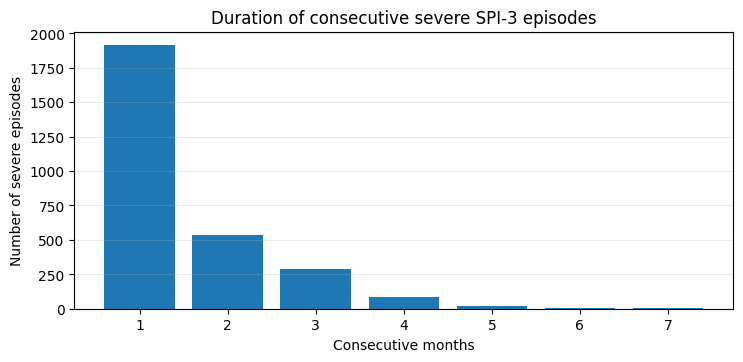

In [4]:
display(severe_episodes.nlargest(10, "duration_months")[["district","region","start_month","end_month","duration_months","lowest_spi3"]])
fig=plot_episode_duration(severe_episodes, OUT / "figures" / "severe_episode_durations.png")
plt.show(); plt.close(fig)

### District map

The choropleth uses NBS 2022 district polygons. Geographic plotting requires the optional `geopandas` package; all numerical analyses run without it.

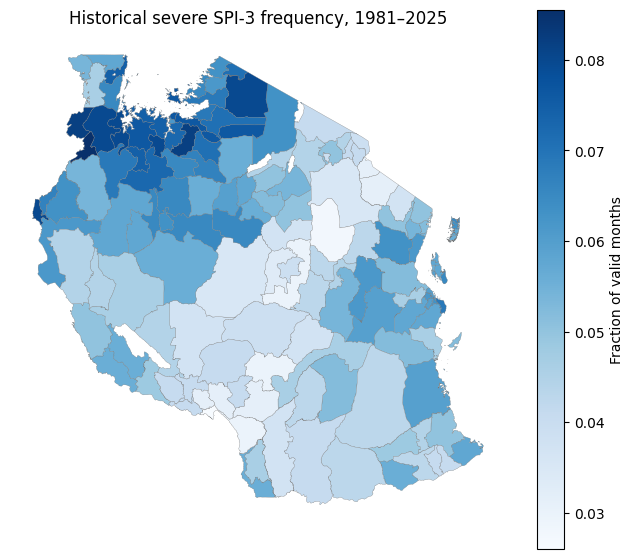

In [5]:
fig=plot_geographic(tables["district"], GEOGRAPHY, OUT / "maps" / "historical_severe_frequency_map.png")
if fig is None:
    print("Install optional geographic dependencies with: pip install -r requirements-maps.txt")
else:
    plt.show(); plt.close(fig)

### Northern Tanzania, 2021–2022

Rainfall totals are compared with 1981–2010 seasonal rainfall means. These seasonal deficits must not be confused with the monthly severe SPI-3 classification.

In [6]:
northern=northern_case_study(data)
display(northern.round(2))
print("Severe SPI-3 months in these three northern districts in 2020–2022:",
      int(classified.loc[classified.district.isin(["Longido","Monduli","Simanjiro"]) & classified.year.between(2020,2022),"is_severe"].sum()))
for name,t in tables.items(): t.to_csv(OUT / "tables" / f"{name}_drought_history.csv", index=False)
severe_episodes.to_csv(OUT / "tables" / "severe_drought_episode_register.csv", index=False)
all_drought_episodes.to_csv(OUT / "tables" / "drought_episode_register.csv", index=False)
northern.to_csv(OUT / "tables" / "northern_2021_2022_rainfall.csv", index=False)

,district,season,rainfall_mm,reference_rainfall_mm,percent_of_reference,last_month_spi3,months_with_severe_spi3
0,Longido,Vuli 2021,124.99,207.46,60.25,-0.74,0
1,Longido,Masika 2022,219.00,342.25,63.99,-1.10,0
2,Monduli,Vuli 2021,97.49,211.51,46.09,-0.93,0
3,Monduli,Masika 2022,240.41,362.02,66.41,-1.06,0
4,Simanjiro,Vuli 2021,92.12,181.67,50.71,-0.87,0
5,Simanjiro,Masika 2022,213.25,343.19,62.14,-1.47,0


Severe SPI-3 months in these three northern districts in 2020–2022: 0


### Interpretation

The SPI-3 reconstruction describes meteorological drought conditions in the supplied index. Reported pastoral drought impacts in 2020–2022 cannot be inferred from SPI-3 alone, especially where local severe thresholds were not crossed.